<a href="https://colab.research.google.com/github/guizyre/metodos_numericos/blob/main/erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.1 Exercício O método “divisão e média”, um método antigo para estimação de raiz
quadrada de um número positivo a, pode ser formulado como
xi+1 =(xi + a/xi)/2

In [7]:
import numpy as np
np.set_printoptions(precision=8,suppress=True)

a = 12
x1 = 1
raiz_exata = a**0.5
for c in range(10):
  x1 = (x1+(a/x1))/2
  erro_relativo = abs((raiz_exata) - x1)/raiz_exata
  print(f"valor estimado: {x1} | erro relativo {erro_relativo}")

valor estimado: 6.5 | erro relativo 0.8763883748662838
valor estimado: 4.173076923076923 | erro relativo 0.20466354244373852
valor estimado: 3.5243264799716414 | erro relativo 0.017385420961876744
valor estimado: 3.464616186413269 | erro relativo 0.00014854393221785855
valor estimado: 3.4641016533502986 | erro relativo 1.1031011351683102e-08
valor estimado: 3.464101615137755 | erro relativo 1.2819751242557095e-16
valor estimado: 3.4641016151377544 | erro relativo 0.0
valor estimado: 3.4641016151377544 | erro relativo 0.0
valor estimado: 3.4641016151377544 | erro relativo 0.0
valor estimado: 3.4641016151377544 | erro relativo 0.0


1.2 Para computadores, o épsilon da máquina, ε, pode ser definido como o menor
número que, adicionado a um, retorna um número maior que um, como definimos anteriormente.
Usando o algoritmo abaixo, implemente um programa que calcula o épsilon da sua máquina.
Compare com os resultados obtidos via numpy.
Passo 1: Defina e = 1
Passo 2: Se 1 + e for menor ou igual a 1, vá para o Passo 5;
caso contrário, vá ao Passo 3
Passo 3: e = e/2
Passo 4: Retorne ao Passo 2
# Passo 5: e = 2 x e


In [7]:
import numpy as np
np.set_printoptions(precision=8,suppress=True)

e = 1.0
while(1.0 + e) > 1:
  e /= 2
e *= 2

print(f"Épsilon: {e}")
print(f"Épsilon numpy: {np.finfo(float).eps}")

Épsilon: 2.220446049250313e-16
Épsilon numpy: 2.220446049250313e-16


Exercício 1.3 Considere o seguinte processo iterativo:
x
(1) =
1
3
x
(n+1) = 4x
(1) − 1, n = 1, 2, . . . (1.51)
Observe que x
(1) =
1
3
, x
(2) = 4 1
3 − 1 = 1
3
, x
(3) = 4 1
3 − 1 = 1
3
, e por aí vai, ou seja, temos
uma sequência constante igual a 1
3
.
Implemente essa série iterativa, verificando se a convergência de fato ocorre e justifique
o resultado obtido.

In [8]:
import numpy as np
np.set_printoptions(precision=8,suppress=True)

x = 1/3
for c in range(30):
    x = (x * 4) - 1
    print(f"intereção: {c+1} com valor de x: {x}")


intereção: 1 com valor de x: 0.33333333333333326
intereção: 2 com valor de x: 0.33333333333333304
intereção: 3 com valor de x: 0.33333333333333215
intereção: 4 com valor de x: 0.3333333333333286
intereção: 5 com valor de x: 0.3333333333333144
intereção: 6 com valor de x: 0.33333333333325754
intereção: 7 com valor de x: 0.33333333333303017
intereção: 8 com valor de x: 0.3333333333321207
intereção: 9 com valor de x: 0.3333333333284827
intereção: 10 com valor de x: 0.3333333333139308
intereção: 11 com valor de x: 0.3333333332557231
intereção: 12 com valor de x: 0.3333333330228925
intereção: 13 com valor de x: 0.3333333320915699
intereção: 14 com valor de x: 0.3333333283662796
intereção: 15 com valor de x: 0.3333333134651184
intereção: 16 com valor de x: 0.33333325386047363
intereção: 17 com valor de x: 0.33333301544189453
intereção: 18 com valor de x: 0.3333320617675781
intereção: 19 com valor de x: 0.3333282470703125
intereção: 20 com valor de x: 0.33331298828125
intereção: 21 com valor 

assim, vemos que a serie diverge na implementação. A cada interação a multiplicação por 4 amplia o erro em uma PG. Mesmo sendo um erro minúsculo, a cada interação o erro vai ficando mais instavel.

Exercício 1.4 Considere as expressões:
exp(1/µ)
1 + exp(1/µ)
(1.52)
e
1
exp(−1/µ) + 1 (1.53)
com µ > 0. Verifique que elas são idênticas como funções reais. Teste no computador cada
uma delas para µ = 0, 1, µ = 0, 01, µ = 0, 001 ou menor e responda: Qual dessas expressões é
mais adequada quando µ é um número pequeno? Por quê?

In [11]:
import numpy as np
np.set_printoptions(precision=8,suppress=True);

u = 0.1;
print(f"{'u':<8} | {'funcao_1 (1.52)':<15} | {'funcao_2 (1.53)':<15}");

for c in range(4):
  funcao_1 = np.exp(1/u) / (1 + np.exp(1/u));
  funcao_2 = 1 / (np.exp(-1/u)+1);
  print(f"{u:<8} | {str(funcao_1):<15} | {funcao_2:<15}");
  u /= 10;



u        | funcao_1 (1.52) | funcao_2 (1.53)
0.1      | 0.9999546021312976 | 0.9999546021312976
0.01     | 1.0             | 1.0            
0.001    | nan             | 1.0            
0.0001   | nan             | 1.0            


/tmp/ipykernel_776/43856088.py:8: RuntimeWarning: overflow encountered in exp
  funcao_1 = np.exp(1/u) / (1 + np.exp(1/u));
/tmp/ipykernel_776/43856088.py:8: RuntimeWarning: invalid value encountered in scalar divide
  funcao_1 = np.exp(1/u) / (1 + np.exp(1/u));


a segunda função em vez de estourar a memória, o computador apenas arredonda esse valor extremamente pequeno para 0.0 evitando que o programa quebre por estouro de memória overflow

In [17]:
import numpy as np
np.set_printoptions(precision=8,suppress=True);

valor = 1 / 1000000000000
for c in range(3):
  f = ((1 + valor) - 1) / valor
  print(f" valor: {f}")
  if c == 1:
    valor/=100
  valor /= 1000

 valor: 1.000088900582341
 valor: 1.1102230246251565
 valor: 0.0


Exercício 1.6 Existem diferentes métodos para calcular aproximadamente o valor de π
computacionalmente. Vários desses métodos usam a aproximação por séries de Taylor para
o arcotangente, definida por:
arctan(x) = x −
x
3
3
+
x
5
5
−
x
7
7
+ · · · =
X∞
n=0
(−1)n x
2n+1
2n + 1
São alguns desses métodos:
a) Fórmula de Machin
π
4
= 4 arctan
1
5
− arctan
1
239
Nota: essa fórmula foi usada em 1949 para calcular o valor de π com 2035 casas decimais
no ENIAC.
b) Fórmula de Hutton
π
4
= arctan
1
2
+ arctan
1
3
c) Fórmula de Clausen
π
4
= 2 arctan
1
3
+ arctan
1
7
d) Fórmula de Dase
π
4
= arctan
1
2
+ arctan
1
5
+ arctan
1
8
Gere gráficos que comparem a evolução do erro em função do número de termos
considerados, para os vinte primeiros termos de cada método descrito acima e comente os
resultados obtidos.

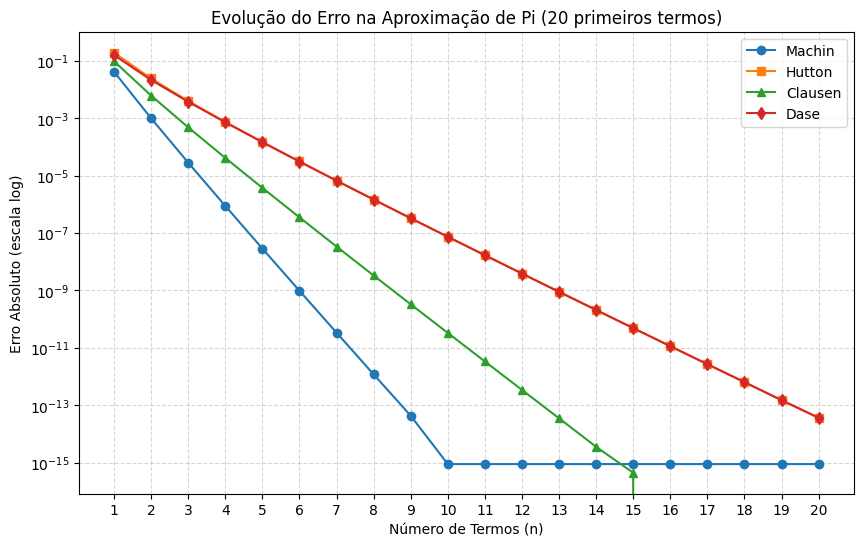

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def arctan_taylor(x, num_termos):
    resultado = 0
    for n in range(num_termos):
        termo = ((-1)**n) * (x**(2*n + 1)) / (2*n + 1)
        resultado += termo
    return resultado

termos = range(1, 21)
erro_machin = []
erro_hutton = []
erro_clausen = []
erro_dase = []

pi_real = np.pi

for N in termos:

    # Machin
    pi_machin = 4 * (4 * arctan_taylor(1/5, N) - arctan_taylor(1/239, N))
    erro_machin.append(abs(pi_machin - pi_real))

    # Hutton
    pi_hutton = 4 * (arctan_taylor(1/2, N) + arctan_taylor(1/3, N))
    erro_hutton.append(abs(pi_hutton - pi_real))

    # Clausen
    pi_clausen = 4 * (2 * arctan_taylor(1/3, N) + arctan_taylor(1/7, N))
    erro_clausen.append(abs(pi_clausen - pi_real))

    # Dase
    pi_dase = 4 * (arctan_taylor(1/2, N) + arctan_taylor(1/5, N) + arctan_taylor(1/8, N))
    erro_dase.append(abs(pi_dase - pi_real))

plt.figure(figsize=(10, 6))

plt.semilogy(termos, erro_machin, marker='o', label='Machin')
plt.semilogy(termos, erro_hutton, marker='s', label='Hutton')
plt.semilogy(termos, erro_clausen, marker='^', label='Clausen')
plt.semilogy(termos, erro_dase, marker='d', label='Dase')

plt.title('Evolução do Erro na Aproximação de Pi (20 primeiros termos)')
plt.xlabel('Número de Termos (n)')
plt.ylabel('Erro Absoluto (escala log)')
plt.xticks(termos)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()